In [2]:
import numpy as np
import pandas as pd
import importlib
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
from tqdm import trange, tqdm
import seaborn as sns
import statsmodels.api as sm
import os
import pipeline_utility
import matplotlib.ticker as ticker

import matplotlib.lines as mlines
import matplotlib.patches as mpatches
%matplotlib inline

In [3]:
def get_abnormality_metrics(experiment, data_folder='data'):
    info_df = pd.DataFrame({'sample' : [], 'usedEntries' : [], 'totalEntries' : [], 'dir' : []})
    for dirpath, dirnames, filenames in os.walk(f'{data_folder}/mergedinfos'):
        for filename in filenames:          
            if filename.endswith('merged.info'):
                filepath = os.path.join(dirpath, filename)
                #mergedinfo_paths.append(filepath)
                new_df = pd.read_csv(filepath, sep='\t')
                new_df['dir'] = dirpath
                info_df = pd.concat([info_df, new_df])
    total_counts = {}
    for dirpath, dirnames, filenames in os.walk(f'{data_folder}/full-barcoded-fish'):
        for filename in filenames:
            if filename.endswith('.allReadCounts'):
                filepath = os.path.join(dirpath, filename)
                sample = filename.replace('.allReadCounts', '')
                read_counts = pd.read_csv(filepath, sep='\t')
                total_counts[sample] = read_counts['count'].sum()
    info_df['trueUsedEntries'] = info_df['sample'].apply(lambda x: total_counts.get(x, 0))
    
    info_df['file'] = info_df['sample']
    info_df['usedEntryProp'] = info_df['usedEntries'] / info_df['totalEntries']
    info_df['trueUsedEntryProp'] = info_df['trueUsedEntries'] / info_df['totalEntries']
    info_df['fish'] = info_df['file'].apply(lambda x: x.split('_')[0])
    info_df['sample'] = info_df['file'].apply(lambda x: x.split('_')[1][1:])
    info_df['replicate'] = info_df['file'].apply(lambda x: x.split('_')[2][3:])
    info_df['sample'] = info_df['sample'].astype(int)
        
    kept_file = f'./experiments/{experiment}/prop_reads_kept.csv'
    kept_df = pd.read_csv(kept_file)
    kept_df.rename(columns={'proportion': 'keptProp'}, inplace=True)
    kept_df['sample'] = kept_df['sample'].astype(int)
    if not 'pass' in kept_df.columns:
        kept_df['pass'] = kept_df['pass_prop'] & kept_df['pass_z']
    return (info_df, kept_df)

In [4]:
def get_missing_values(arr):
    missing = []
    for val in range(arr.min(), arr.max()):
        if not val in arr:
            missing.append(val)
    return np.array(missing)

def interpolate(df):
    concat = {'barcode': [], 'sample': [], 'proportion': []}
    barcodes = df['barcode'].unique()
    for barcode in barcodes:
        x_known = df['sample'].astype('int32').unique()
        y_known = np.array(df[df['barcode'] == barcode]['proportion'], dtype='float64')
        x_desired = get_missing_values(x_known)
        interpolated_values = np.interp(x_desired, x_known, y_known)
        # Add interpolated values to the dataframe
        concat['barcode'] += [barcode] * len(interpolated_values)
        concat['sample'] += x_desired.tolist()
        concat['proportion'] += interpolated_values.tolist()
    return pd.DataFrame(concat)

In [41]:
def plot_fish(fish, ax, all_data, abnormalities = []):
    fish_data = all_data.query('fish == @fish').copy()
    fish_data = fish_data[~fish_data['sample'].isin(abnormalities)]
    #barcodes = np.unique(fish_data['barcode'])
    pipeline_utility.plot_muller(all_data, fish, ax, map_samples=True)
    ax.set_title(f'{fish}')
    plt.tight_layout()

def show_abnormalities(fish, axis, all_data, metrics, interp = True, show_used=True, show_filtered=True, show_visual=True, map_samples=False, show_cutoff=True):
    #fish = fishes[index]
    fish_data = all_data.query('fish == @fish').copy()
    aggregated_df = fish_data.groupby(['barcode', 'sample']).agg({'proportion': 'mean'}).reset_index().fillna(0)
    # Fill in values with 0 where the proportion doesn't exist for a certain barcode/sample combo
    pivot_table_df = aggregated_df.pivot_table(index='barcode', columns='sample', values='proportion', fill_value=0).reset_index()
    if interp:
        final_df_nointerp = pivot_table_df.melt(id_vars='barcode', var_name='sample', value_name='proportion')
        final_df = pd.concat([final_df_nointerp, interpolate(final_df_nointerp)])
    else:
        final_df = pivot_table_df.melt(id_vars='barcode', var_name='sample', value_name='proportion')

    if show_visual:
        # Difference between std of window and std of window excluding central element
        stds = {'sample' : [], 'std included' : [], 'std excluded' : []}
        window = 2
        for sample in range(final_df['sample'].min(), final_df['sample'].max() + 1):
            sum_std_included = 0
            sum_std_excluded = 0
            for barcode in fish_data['barcode'].unique():
                filtered_data_included = final_df[(final_df['barcode'] == barcode) & (abs(final_df['sample'] - sample) <= window)]['proportion']
                filtered_data_excluded = final_df[(final_df['barcode'] == barcode) & (final_df['sample'] != sample) & (abs(final_df['sample'] - sample) <= window)]['proportion']
                std_included = filtered_data_included.std()
                std_excluded = filtered_data_excluded.std()
                sum_std_included += std_included
                sum_std_excluded += std_excluded
            stds['sample'].append(sample)
            stds['std included'].append(sum_std_included)
            stds['std excluded'].append(sum_std_excluded)
        stdf = pd.DataFrame(stds).set_index('sample')
        stdf['val'] = stdf['std included'] - stdf['std excluded']

        # Plot
        stdf.drop(columns = ['std included', 'std excluded']).plot(ax=axis)
        
        # Detect visual anomalies
        differences = {}
        for sample in stdf.index:
            left = 0
            right = 0
            if sample - 1 in stdf.index:
                left = stdf.loc[sample,'val'] - stdf.loc[sample - 1,'val']
            if sample + 1 in stdf.index:
                right = stdf.loc[sample,'val'] - stdf.loc[sample + 1,'val']
            differences[sample] = (left, right)
        stdf['abnormality'] = stdf.index.map(lambda sample: differences[sample][0] > 0.2 and differences[sample][1] > 0.2)
        
        # Plot visual anomalies
        axis.scatter(stdf[stdf['abnormality']].index, stdf[stdf['abnormality']]['val'], color='blue', alpha=0.5)
        axis.legend().remove()

    #Set colors
    used_entries_color = 'red'
    kept_values_color = 'purple'
    
    # Plot proportion of used and filtered entries
    if show_used:
        show_used_entries(metrics[0], fish, axis, used_entries_color, map_samples, show_cutoff)
    if show_filtered:
        show_filtered_proportion(metrics[1], fish, axis, kept_values_color, map_samples, show_cutoff)

    axis.set_xlabel('Time')
    axis.set_ylabel(None)
    xticks = np.unique(np.append(metrics[0][metrics[0]['fish'] == fish]['sample'], metrics[1][metrics[1]['fish'] == fish]['sample']))
    if map_samples:
        axis.set_xticks(np.array([pipeline_utility.sample_map[x] for x in xticks]))
    else:
        axis.set_xticks(xticks)
    axis.set_ylim(0, 1)

# Plot the proportion of entries used by GESTALT
def show_used_entries(info_df, fish, axis, col, map_samples, show_cutoff):
    fish_data = info_df.query('fish == @fish').copy()
    if map_samples:
        fish_data['sample'] = fish_data['sample'].map(lambda x: pipeline_utility.sample_map[x])
            
    fish_data['outlier'] = fish_data['trueUsedEntryProp'] < 0.3

    # Fake usedProp
    #axis.plot(fish_data['sample'], fish_data['usedEntryProp'], color=col, marker='s', linestyle='', markersize=5, alpha=0.5)
    # True usedProp
    axis.plot(fish_data['sample'], fish_data['trueUsedEntryProp'], color=col, marker='s', linestyle='', markersize=5, alpha=0.5)
    axis.plot(fish_data[fish_data['outlier']]['sample'], fish_data[fish_data['outlier']]['trueUsedEntryProp'], color=col, marker='x', linestyle='', markersize=10)
    if show_cutoff:
        outlier = 0.3
        domain = np.array(range(fish_data['sample'].min(), fish_data['sample'].max() + 1))
        axis.plot(domain, np.repeat(outlier, len(domain)), color=col, linestyle='--', alpha=0.5)

# Plot the proportion of reads that remained after the filtering pipeline
def show_filtered_proportion(kept_df, fish, axis, col, map_samples, show_cutoff):
    fish_data = kept_df.query('fish == @fish').copy()
    if map_samples:
        fish_data['sample'] = fish_data['sample'].map(lambda x: pipeline_utility.sample_map[x])
    
    axis.plot(fish_data['sample'], fish_data['keptProp'], color=col, marker='^', linestyle='', markersize=5, alpha=0.5)
    axis.plot(fish_data[~fish_data['pass']]['sample'], fish_data[~fish_data['pass']]['keptProp'], color=col, marker='x', linestyle='', markersize=10)
    if show_cutoff:
        mean = fish_data['mean'].head(1).item()
        std = fish_data['std'].head(1).item()
        outlier = max(mean - 3 * std, 0.3)
        domain = np.array(range(fish_data['sample'].min(), fish_data['sample'].max() + 1))
        axis.plot(domain, np.repeat(outlier, len(domain)), color=col, linestyle='--', alpha=0.5)

In [59]:
fig, ax = plt.subplots(dpi=300)
show_abnormalities(0, ax, data, interp = False, show_used=True)

plt.show()

TypeError: show_abnormalities() missing 1 required positional argument: 'metrics'

In [ ]:
fig, ax = plt.subplots(len(fishes), 2, figsize = (6, 2*len(fishes)), dpi=400)

#plt.rcParams['xtick.labelsize'] = 10 # For x-axis tick labels
#plt.rcParams['ytick.labelsize'] = 10 # For y-axis tick labels
for i, fish in enumerate(fishes):
    plot_fish(fish, ax[i, 0], data)
    ax[i, 0].tick_params(axis='x', labelsize=8)
    abnormalities = show_abnormalities(i, ax[i, 1], interp = False)
    ax[i, 1].tick_params(axis='x', labelsize=8)
    # Force integer tick labels on the x-axis
    ax[i, 1].xaxis.set_major_locator(MaxNLocator(integer=True))
plt.tight_layout()

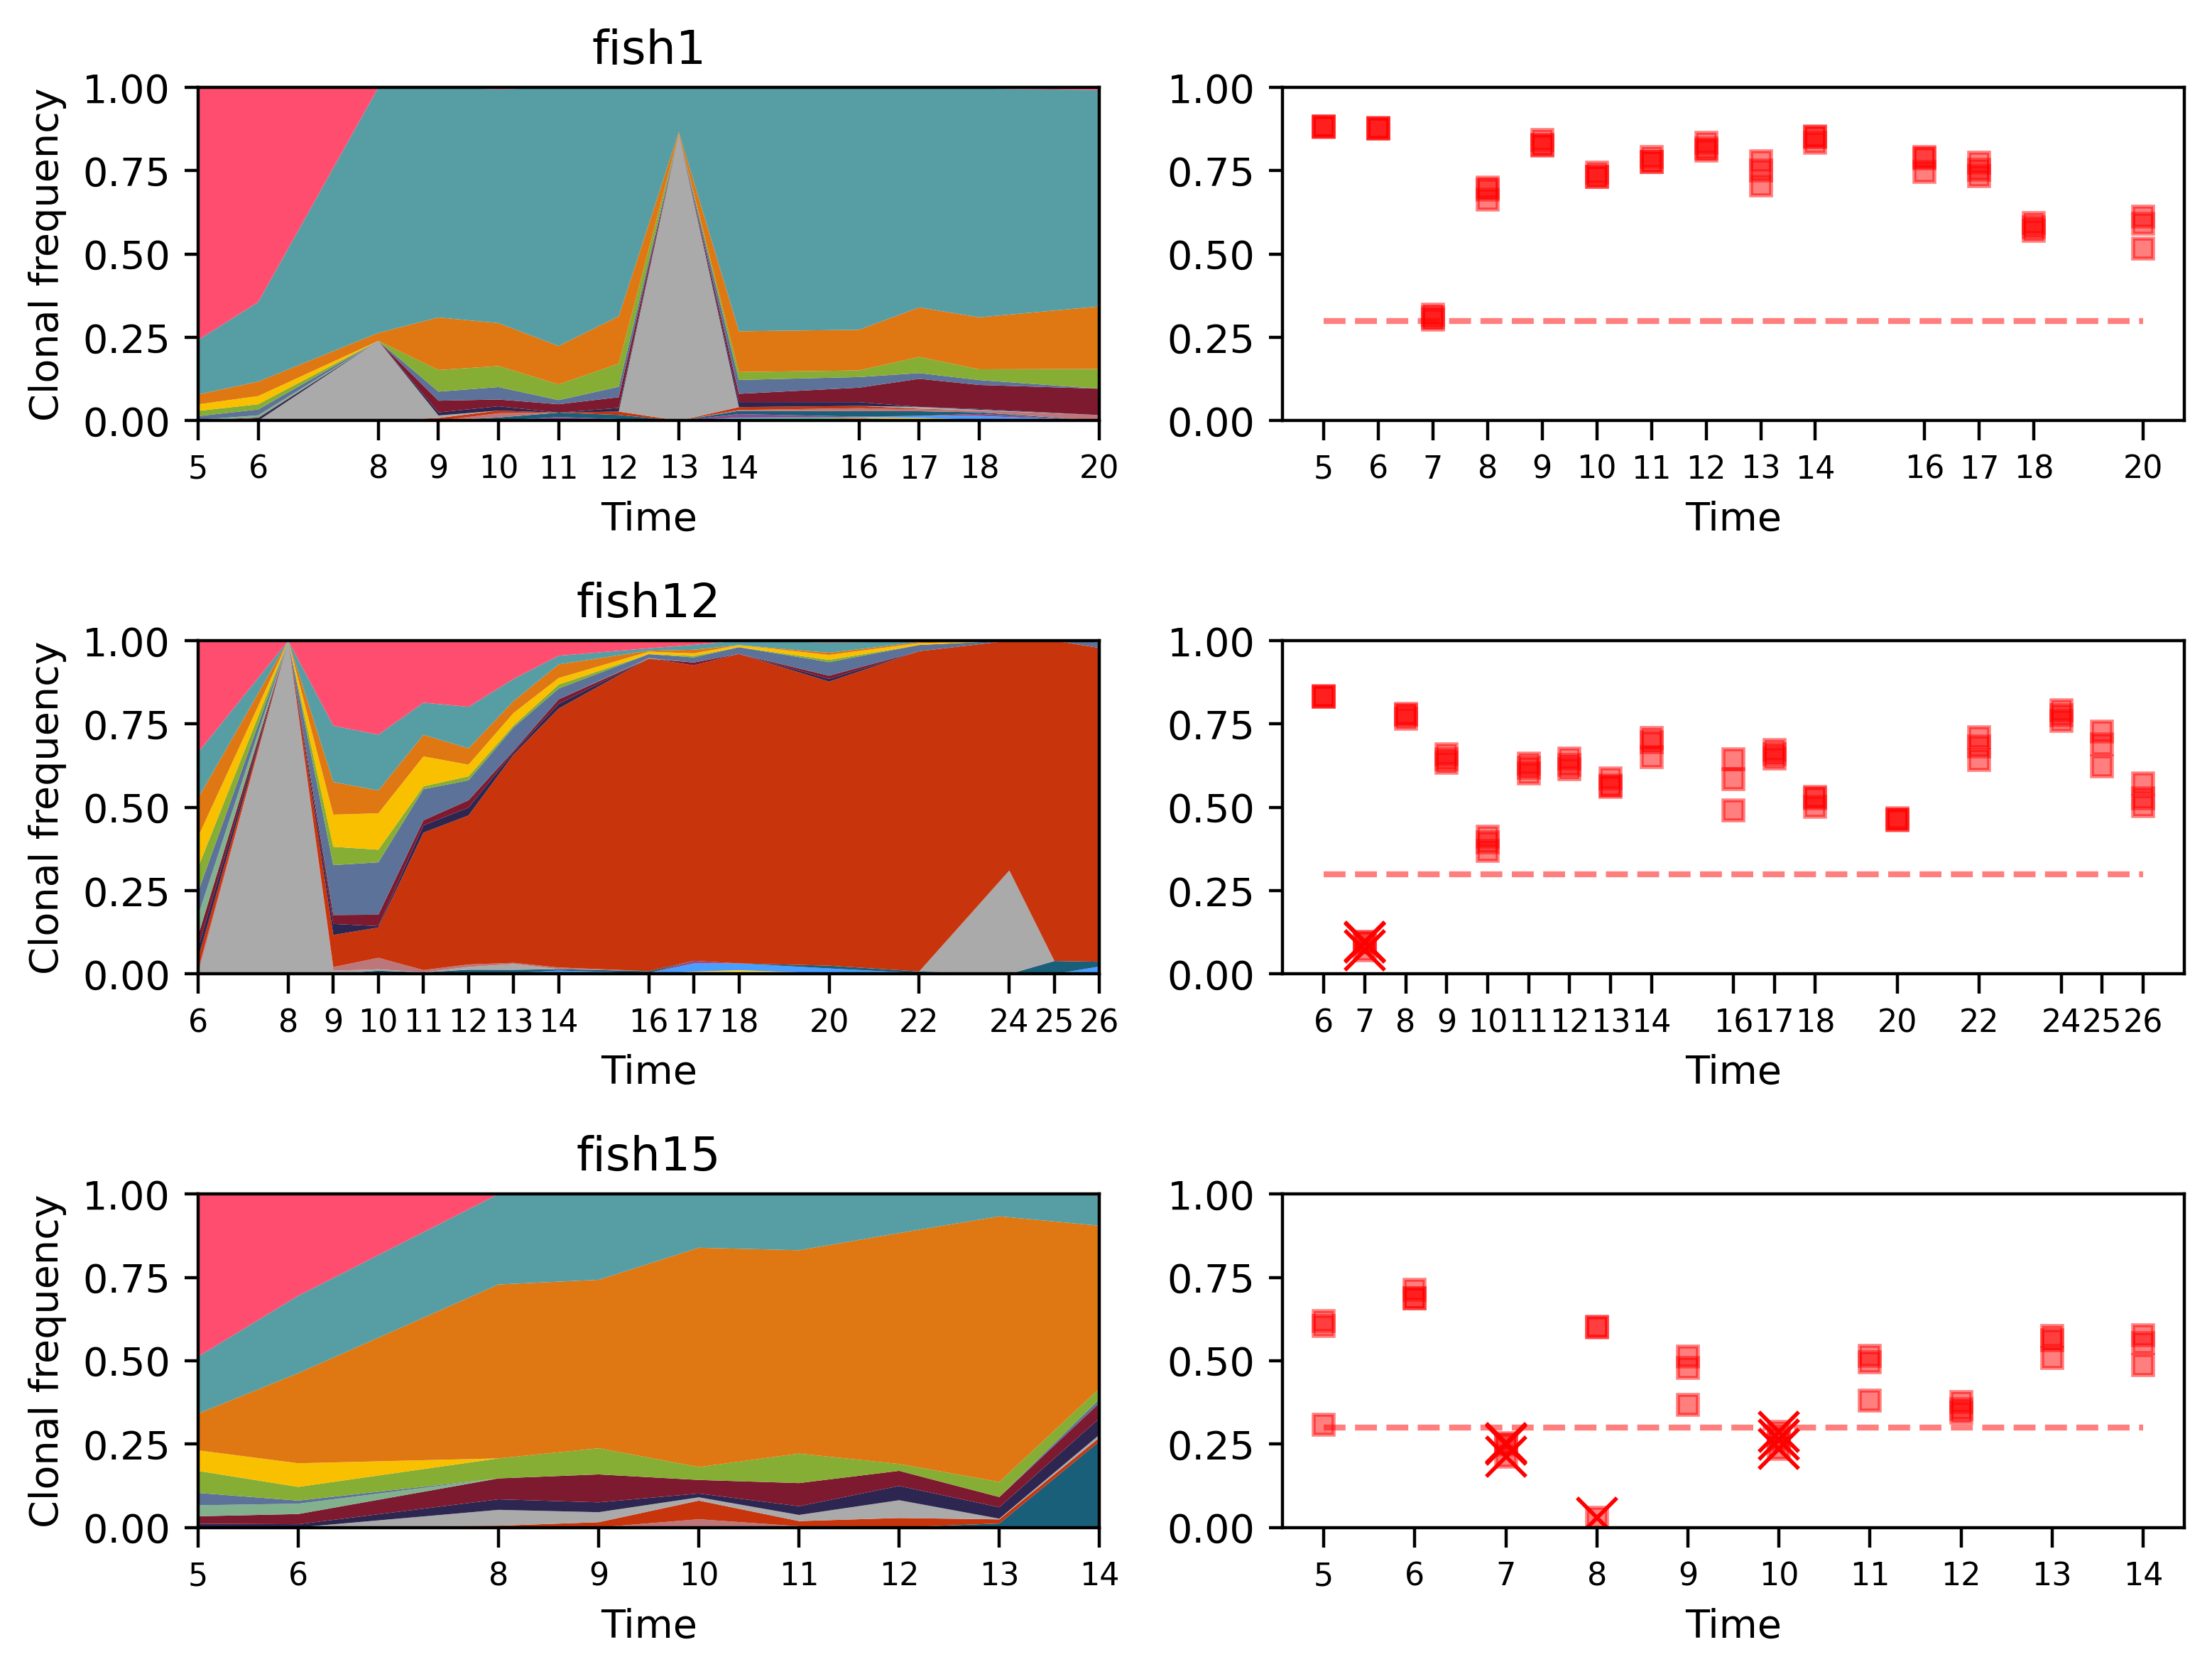

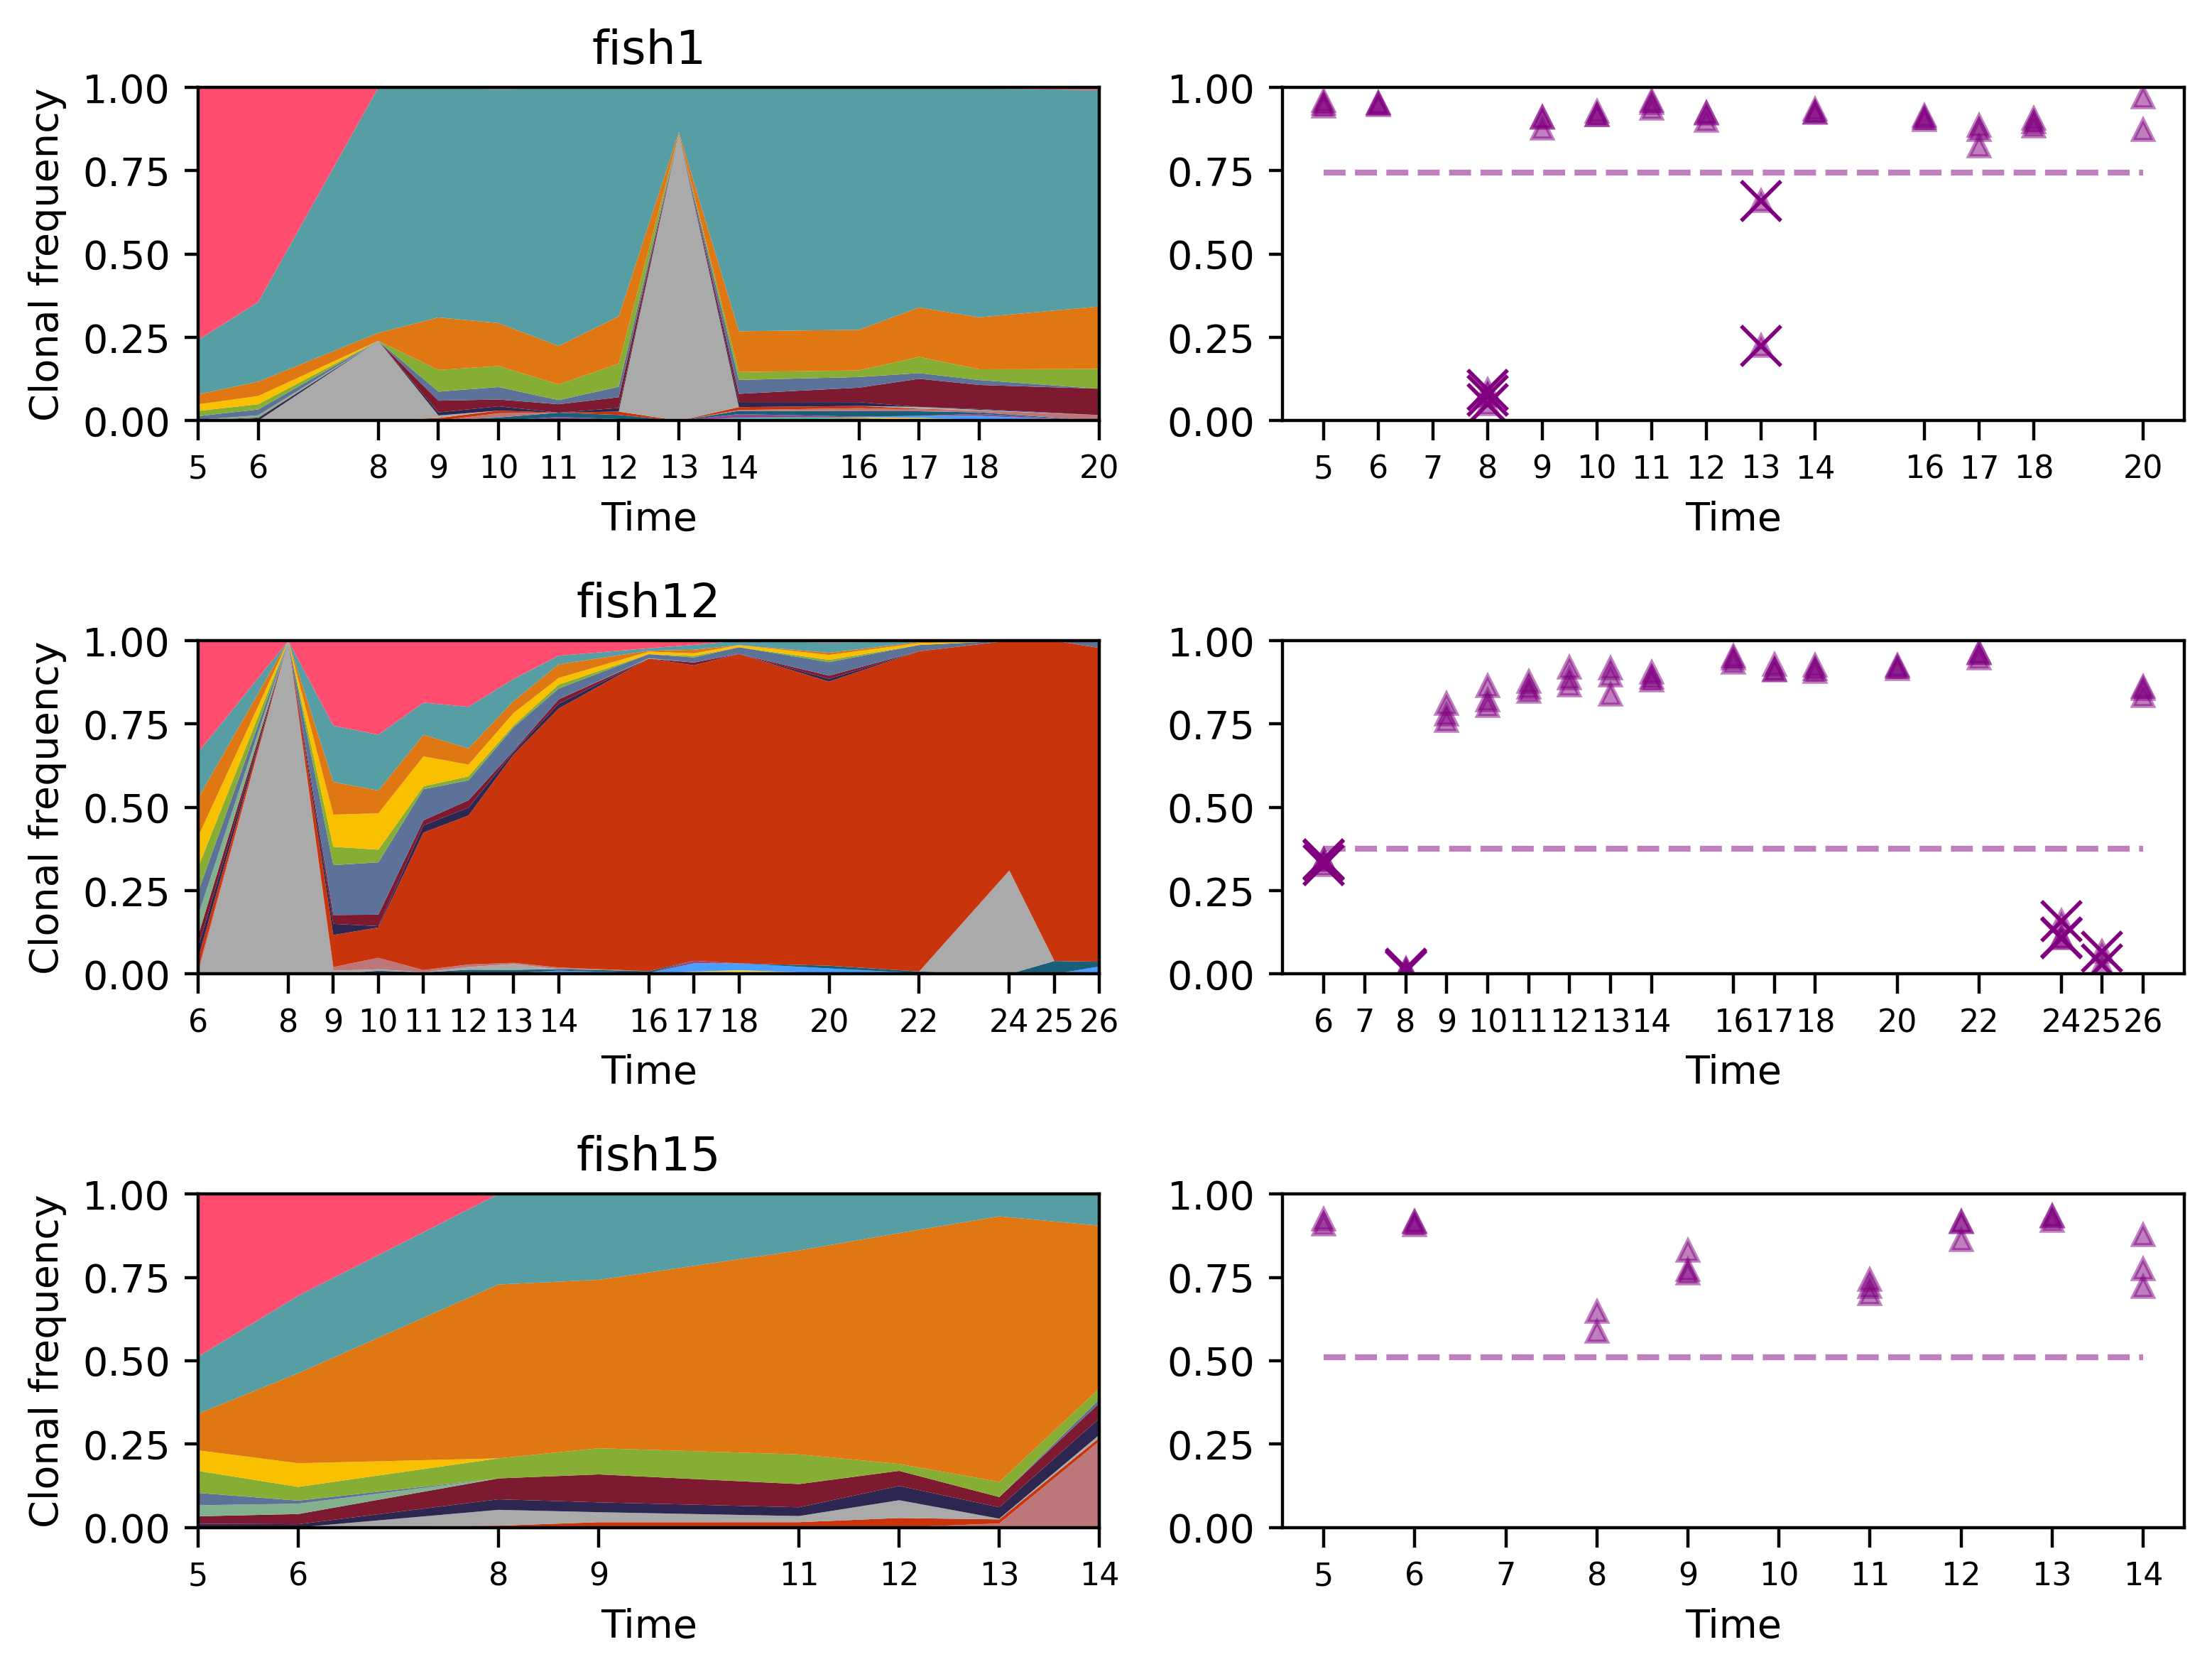

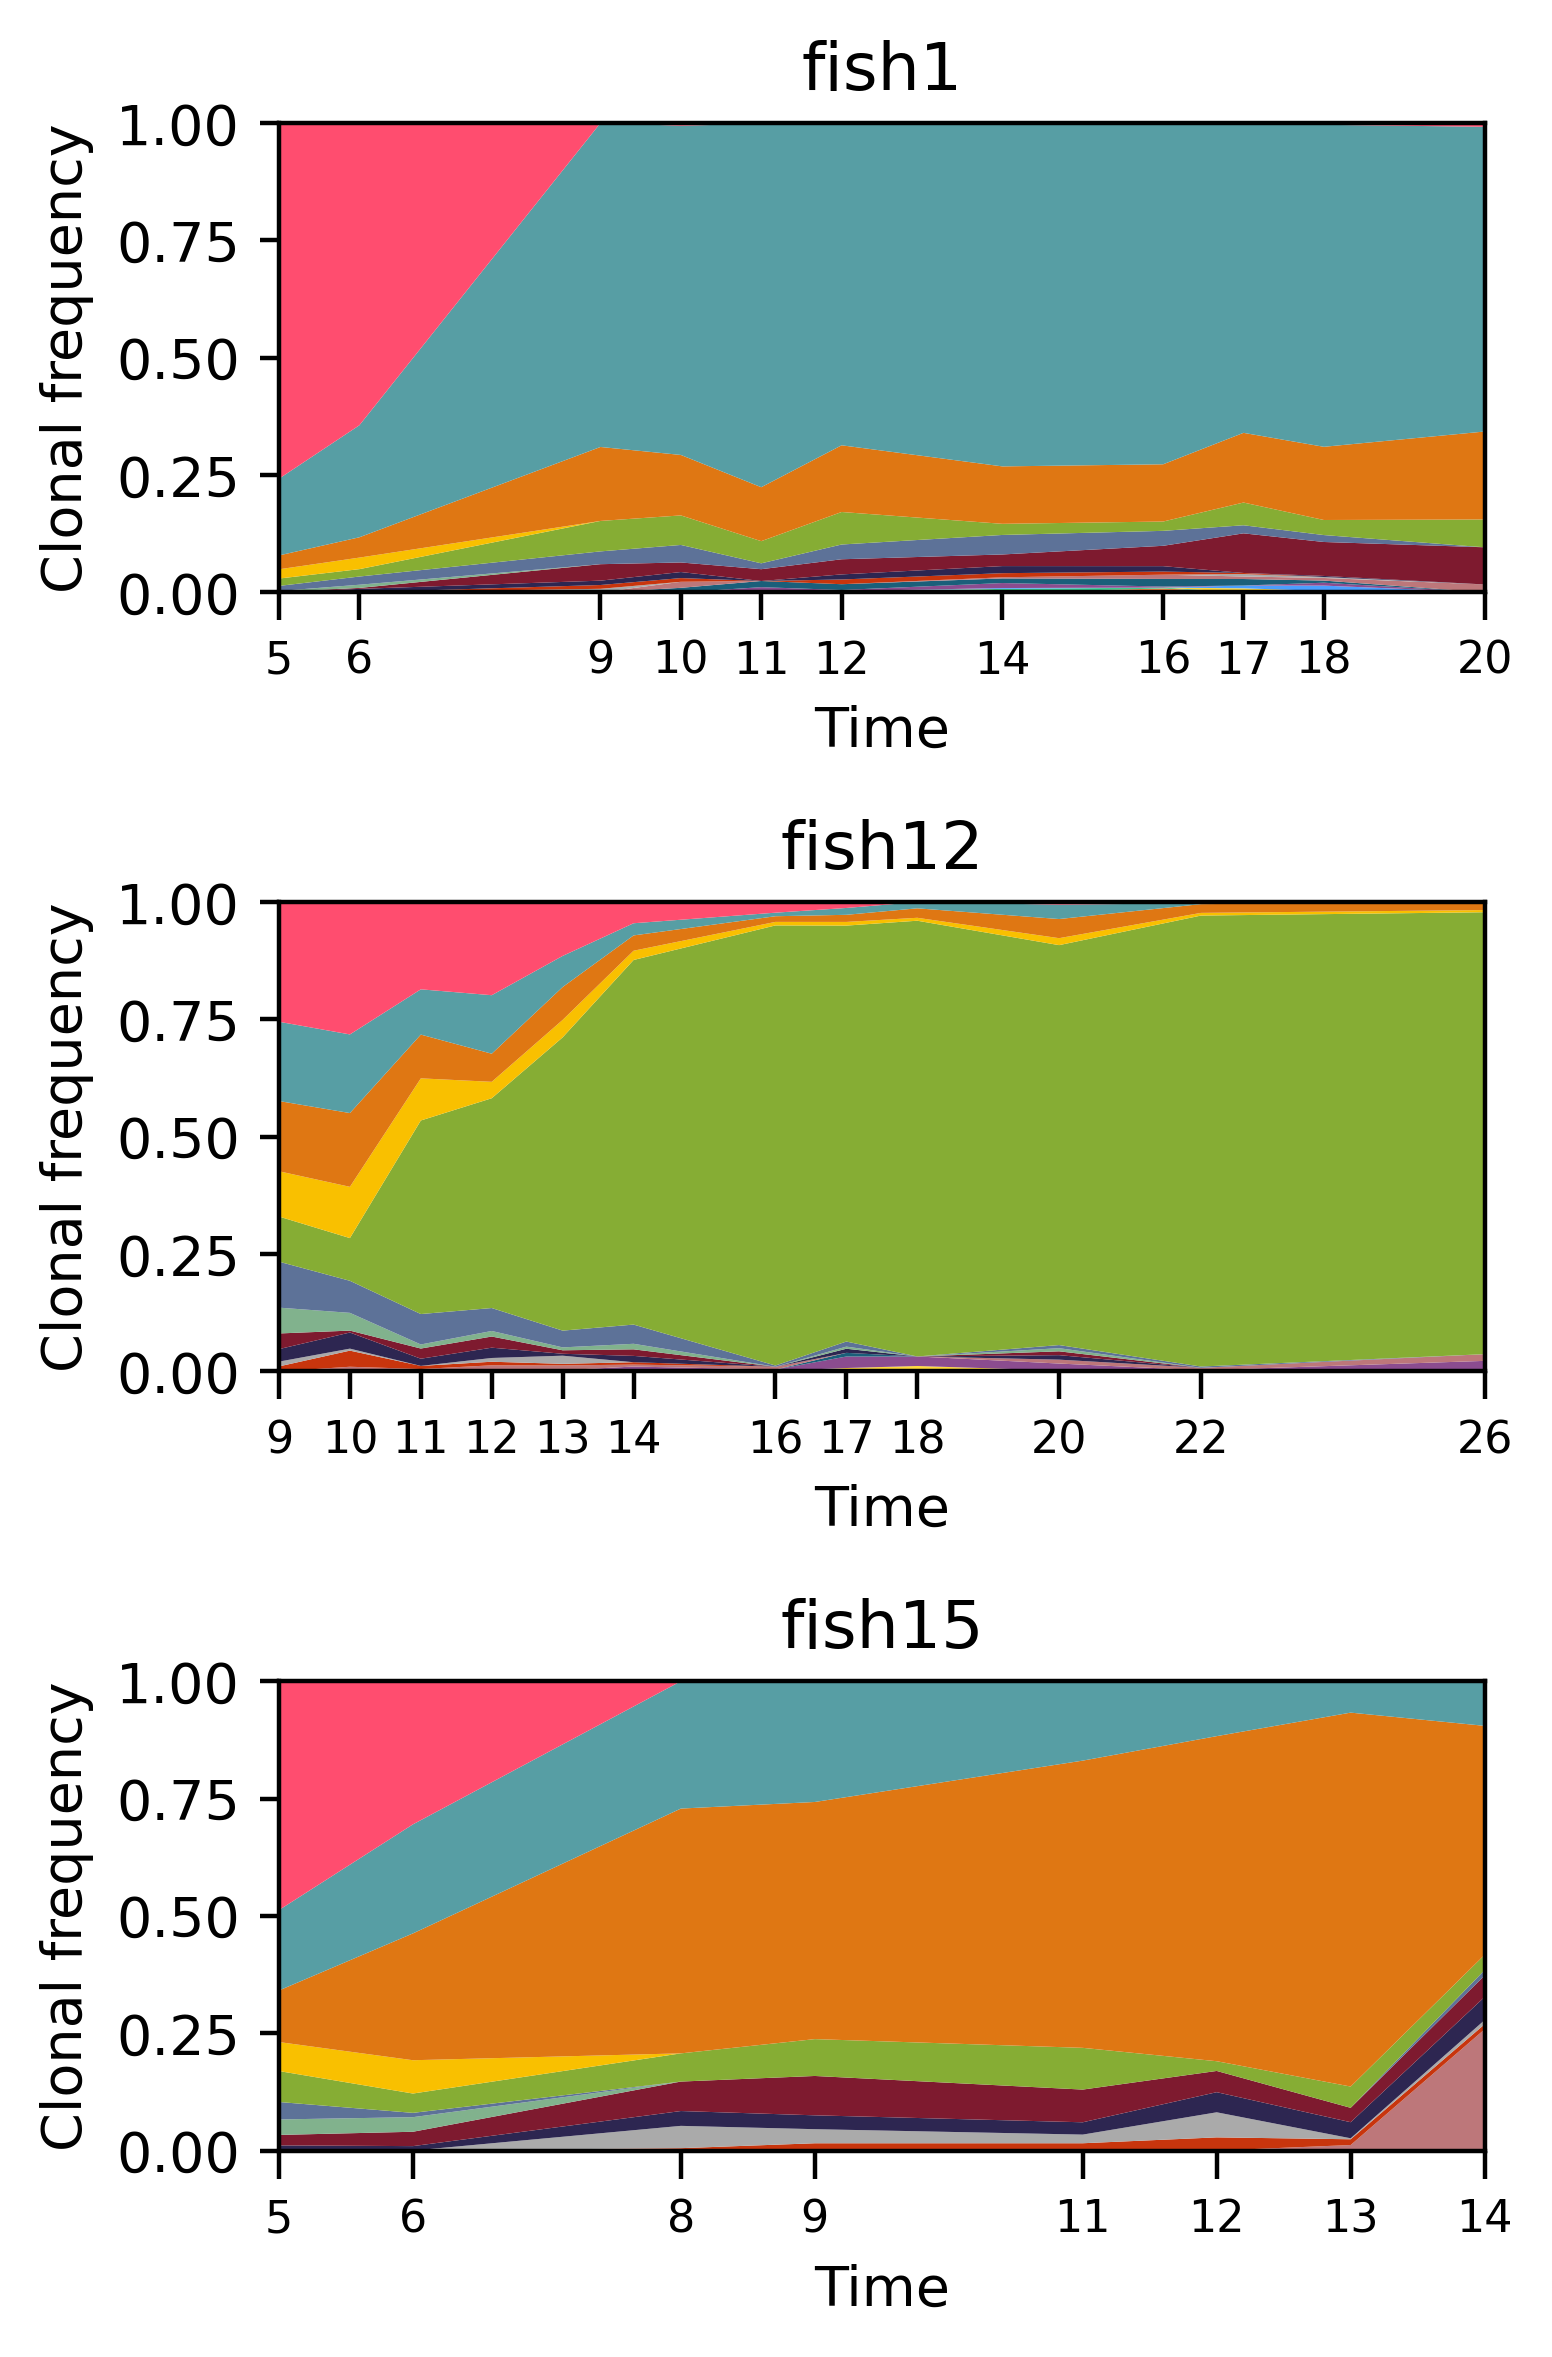

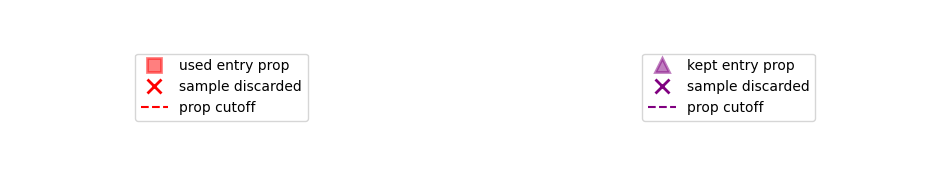

In [42]:
# Show mullers before and after anomaly detection

experiment1 = 'experiment-OG-nofilters'
data_file1 = f'./experiments/{experiment1}/final_data.csv'
data1 = pd.read_csv(data_file1)
metrics1 = get_abnormality_metrics(experiment1, data_folder='data/mp0.8_tq10')

experiment2 = 'experiment-OG-usedfilter'
data_file2 = f'./experiments/{experiment2}/final_data.csv'
data2 = pd.read_csv(data_file2)
metrics2 = get_abnormality_metrics(experiment2, data_folder='data/mp0.8_tq10')

experiment3 = 'experiment-OG'
data_file3 = f'./experiments/{experiment3}/final_data.csv'
data3 = pd.read_csv(data_file3)

# Get the array of fishes we want to plot (cherry-picked for filter demonstration)
fishes_to_plot = ['fish1', 'fish12', 'fish15']
fishes = fishes_to_plot

#fishes = data1['fish'].unique()

# Create custom legends
legend1_elements = [
    # Red square for "used entry prop"
    plt.Line2D([0], [0], marker='s', color='red', markerfacecolor='red', 
               markersize=10, markeredgewidth=2, linestyle='None', alpha=0.5, 
               label='used entry prop'),
    plt.Line2D([0], [0], marker='x', color='red', markerfacecolor='red', 
               markersize=10, markeredgewidth=2, linestyle='None', 
               label='sample discarded'),
    plt.Line2D([0], [0], marker='None', color='red', markerfacecolor='purple', 
               markersize=10, markeredgewidth=2, linestyle='--',
               label='prop cutoff'),

]
legend2_elements = [
    # Purple triangle for "kept entry prop"
    plt.Line2D([0], [0], marker='^', color='purple', markerfacecolor='purple', 
               markersize=10, markeredgewidth=2, linestyle='None', alpha=0.5, 
               label='kept entry prop'),
    plt.Line2D([0], [0], marker='x', color='purple', markerfacecolor='purple', 
               markersize=10, markeredgewidth=2, linestyle='None',
               label='sample discarded'),
    plt.Line2D([0], [0], marker='None', color='purple', markerfacecolor='purple', 
               markersize=10, markeredgewidth=2, linestyle='--',
               label='prop cutoff'),

]

# Section A
fig_width = 2 * 4  # 4 inches per column
fig_height = len(fishes) * 2

fig, ax = plt.subplots(len(fishes), 2, figsize=(fig_width, fig_height), dpi=400)

for i, fish in enumerate(fishes):
    plot_fish(fish, ax[i, 0], data1)
    show_abnormalities(fish, ax[i, 1], data1, metrics1, interp = False, show_filtered=False, show_visual=False, map_samples=True)
    ax[i, 0].tick_params(axis='x', labelsize=8, length=5)
    ax[i, 1].tick_params(axis='x', labelsize=8, length=5)
plt.savefig(f'figures/no-filters.svg', format='svg')
plt.show()

# Section B
fig_width = 2 * 4  # 4 inches per column
fig_height = len(fishes) * 2

fig, ax = plt.subplots(len(fishes), 2, figsize=(fig_width, fig_height), dpi=400)

for i, fish in enumerate(fishes):
    plot_fish(fish, ax[i, 0], data2)
    show_abnormalities(fish, ax[i, 1], data2, metrics2, interp = False, show_used=False, show_visual=False, map_samples=True)
    ax[i, 0].tick_params(axis='x', labelsize=8, length=5)
    ax[i, 1].tick_params(axis='x', labelsize=8, length=5)

plt.savefig(f'figures/first-filter.svg', format='svg')
plt.show()

# Section B
fig_width = 1 * 4  # 4 inches per column
fig_height = len(fishes) * 2

fig, ax = plt.subplots(len(fishes), 1, figsize=(fig_width, fig_height), dpi=400)

# Section C
for i, fish in enumerate(fishes):
    plot_fish(fish, ax[i], data3)
    ax[i].tick_params(axis='x', labelsize=8, length=5)
plt.savefig(f'figures/all-filters.svg', format='svg')
plt.show()

# Plot each fish at each step of the anomaly filtering
# In between steps, plot anomaly metrics
'''for i, fish in enumerate(fishes):
    ax_index = i
    plot_fish(fish, ax[ax_index, 0], data1)
    ax[ax_index, 0].tick_params(axis='x', labelsize=8)
    plot_fish(fish, ax[ax_index, 2], data2)
    ax[ax_index, 2].tick_params(axis='x', labelsize=8)
    plot_fish(fish, ax[ax_index, 4], data3)
    ax[ax_index, 4].tick_params(axis='x', labelsize=8)
    show_abnormalities(fish, ax[ax_index, 1], data1, metrics1, interp = False, show_filtered=False, show_visual=False, map_samples=True)
    show_abnormalities(fish, ax[ax_index, 3], data2, metrics2, interp = False, show_used=False, show_visual=False, map_samples=True)

plt.show()

# Show legends
ax[0, 1].legend(bbox_to_anchor=(0., 1.02, 1., .102), loc='lower center',
                ncol=1, mode="expand", borderaxespad=1.,
                handles=legend1_elements)
ax[0, 3].legend(bbox_to_anchor=(0., 1.02, 1., .102), loc='lower center',
                ncol=1, mode="expand", borderaxespad=1.,
                handles=legend2_elements)
'''

fig, ax = plt.subplots(1, 2, figsize=(12, 2))
ax[0].set_axis_off()
ax[1].set_axis_off()

legend = ax[0].legend(handles=legend1_elements, 
                   loc='center', 
                   ncol=1,  # Display in 1 columns
                   frameon=True)  # Keep frame

legend = ax[1].legend(handles=legend2_elements, 
                   loc='center', 
                   ncol=1,  # Display in 1 columns
                   frameon=True)  # Keep frame

plt.savefig(f'figures/legend_seperate.svg', format='svg')
plt.show()

In [ ]:
# Compare samples with and without certain steps

experiment1 = '-B1'
data_file1 = f'./experiments/{experiment1}/final_data.csv'
data1 = pd.read_csv(data_file1)

experiment2 = '-C'
data_file2 = f'./experiments/{experiment2}/final_data.csv'
data2 = pd.read_csv(data_file2)

experiment3 = '-C-E'
data_file3 = f'./experiments/{experiment3}/final_data.csv'
data3 = pd.read_csv(data_file3)

fishes = data1['fish'].unique()

fig, ax = plt.subplots(len(fishes), 3, figsize = (6, 2*len(fishes)), dpi=400)

#plt.rcParams['xtick.labelsize'] = 10 # For x-axis tick labels
#plt.rcParams['ytick.labelsize'] = 10 # For y-axis tick labels
for i, fish in enumerate(fishes):
    plot_fish(fish, ax[i, 0], data1)
    ax[i, 0].tick_params(axis='x', labelsize=8)
    plot_fish(fish, ax[i, 1], data2)
    ax[i, 1].tick_params(axis='x', labelsize=8)
    plot_fish(fish, ax[i, 2], data3)
    ax[i, 2].tick_params(axis='x', labelsize=8)
plt.tight_layout()
plt.show()

In [112]:
# Compare mullers for two sets of GESTALT parameters
# ALL fish

experiment1 = 'params_old'
data_file1 = f'./experiments/{experiment1}/final_data.csv'
data1 = pd.read_csv(data_file1)
#data1 = data1.query('sample > 4').copy()
metrics1 = get_abnormality_metrics(experiment1, data_folder='data')

experiment2 = 'experiment-TQ14'
data_file2 = f'./experiments/{experiment2}/final_data.csv'
data2 = pd.read_csv(data_file2)
metrics2 = get_abnormality_metrics(experiment2, data_folder='data-MP0.95')

fishes = data2['fish'].unique()

fig_width = 4 * 4  # 4 inches per column
fig_height = 2 * len(fishes)

fig, ax = plt.subplots(len(fishes), 4, figsize=(fig_width, fig_height), dpi=400)

#plt.rcParams['xtick.labelsize'] = 10 # For x-axis tick labels
#plt.rcParams['ytick.labelsize'] = 10 # For y-axis tick labels
for i, fish in enumerate(fishes):
    plot_fish(fish, ax[i, 0], data1)
    ax[i, 0].tick_params(axis='x', labelsize=8)
    plot_fish(fish, ax[i, 2], data2)
    ax[i, 1].tick_params(axis='x', labelsize=8)

    show_abnormalities(i, ax[i, 1], data1, metrics1, interp = False, show_visual=False)
    show_abnormalities(i, ax[i, 3], data2, metrics2, interp = False, show_visual=False)
plt.tight_layout()
plt.show()

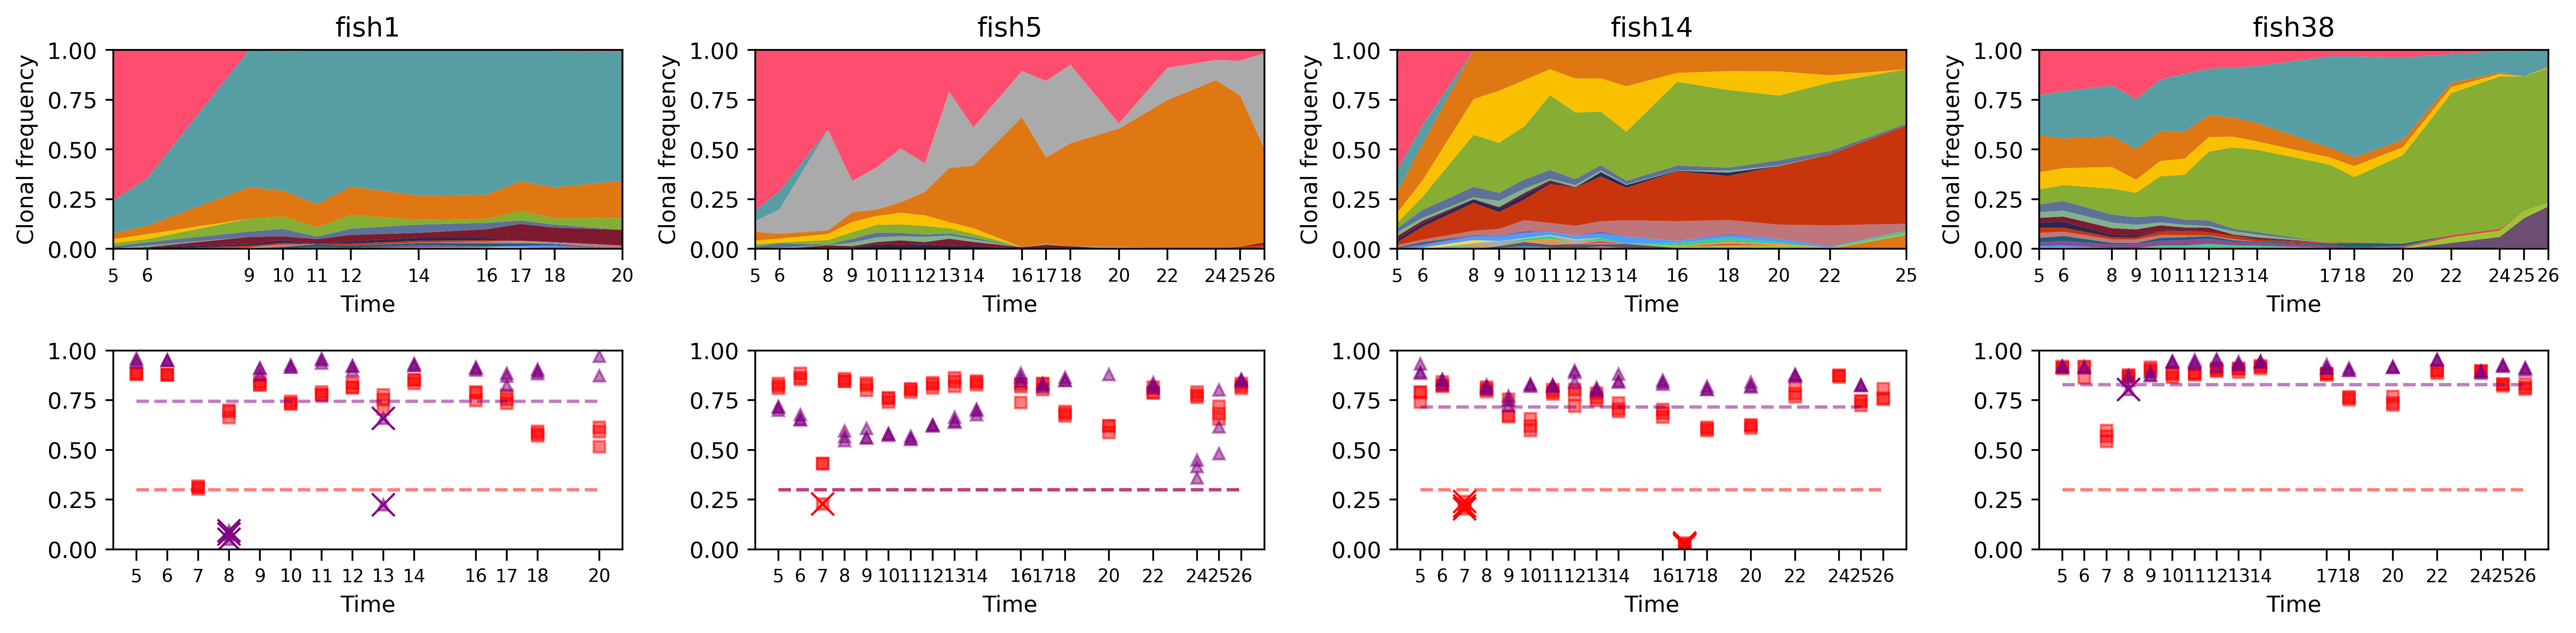

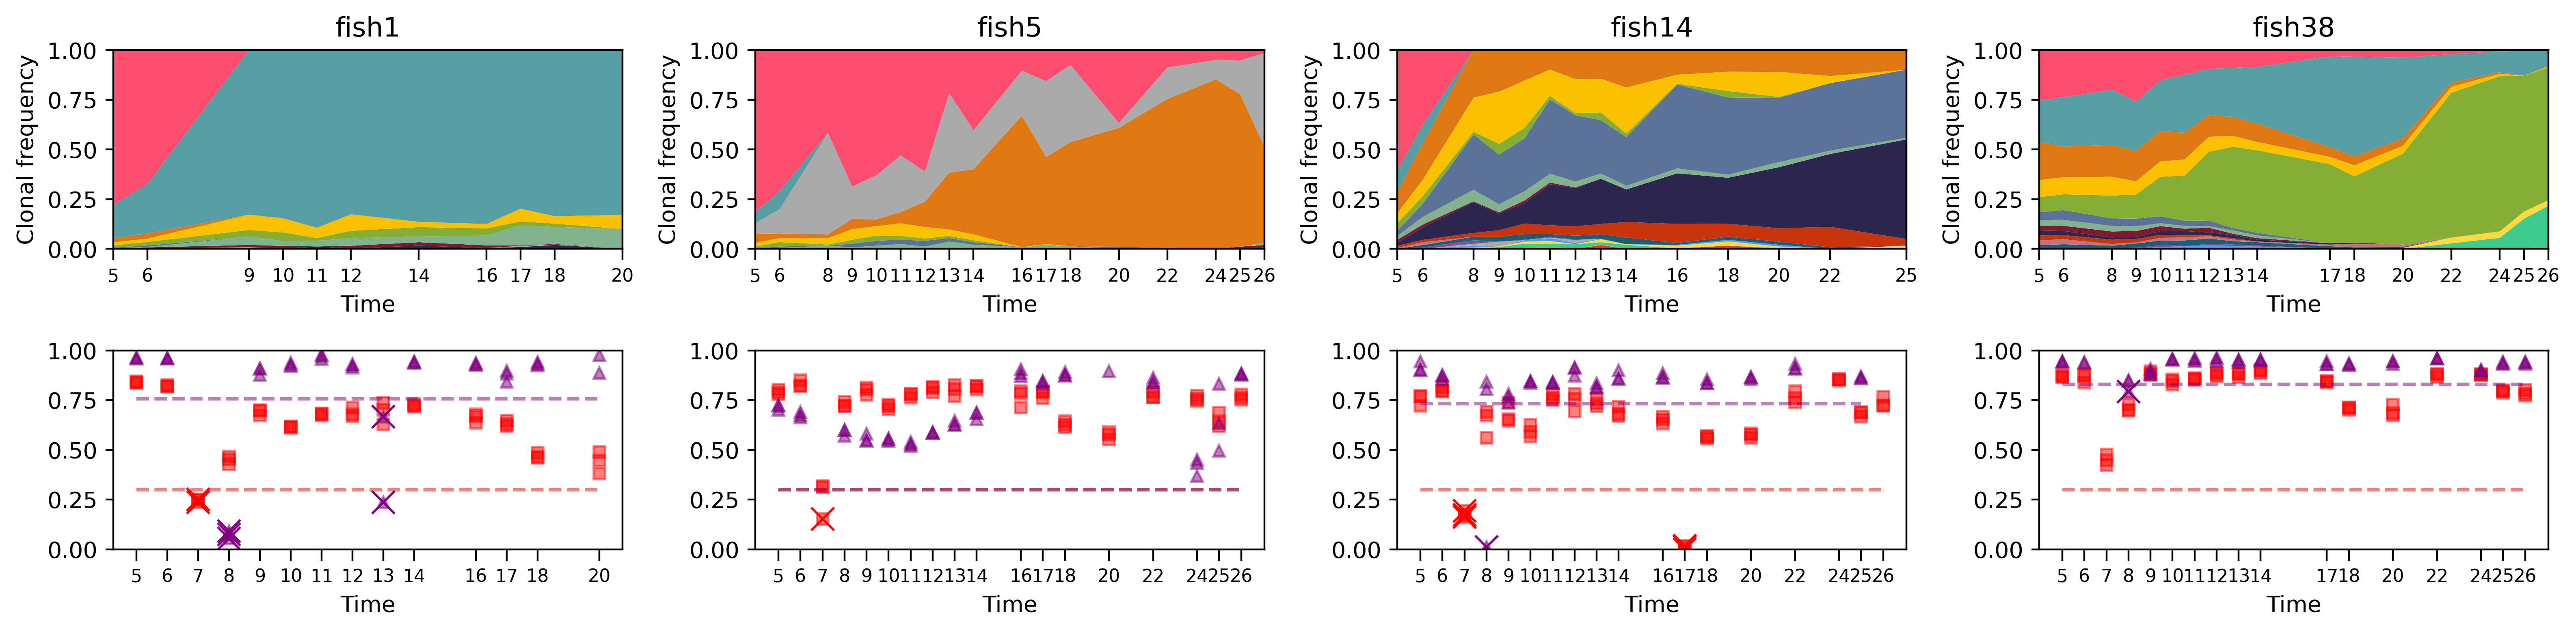

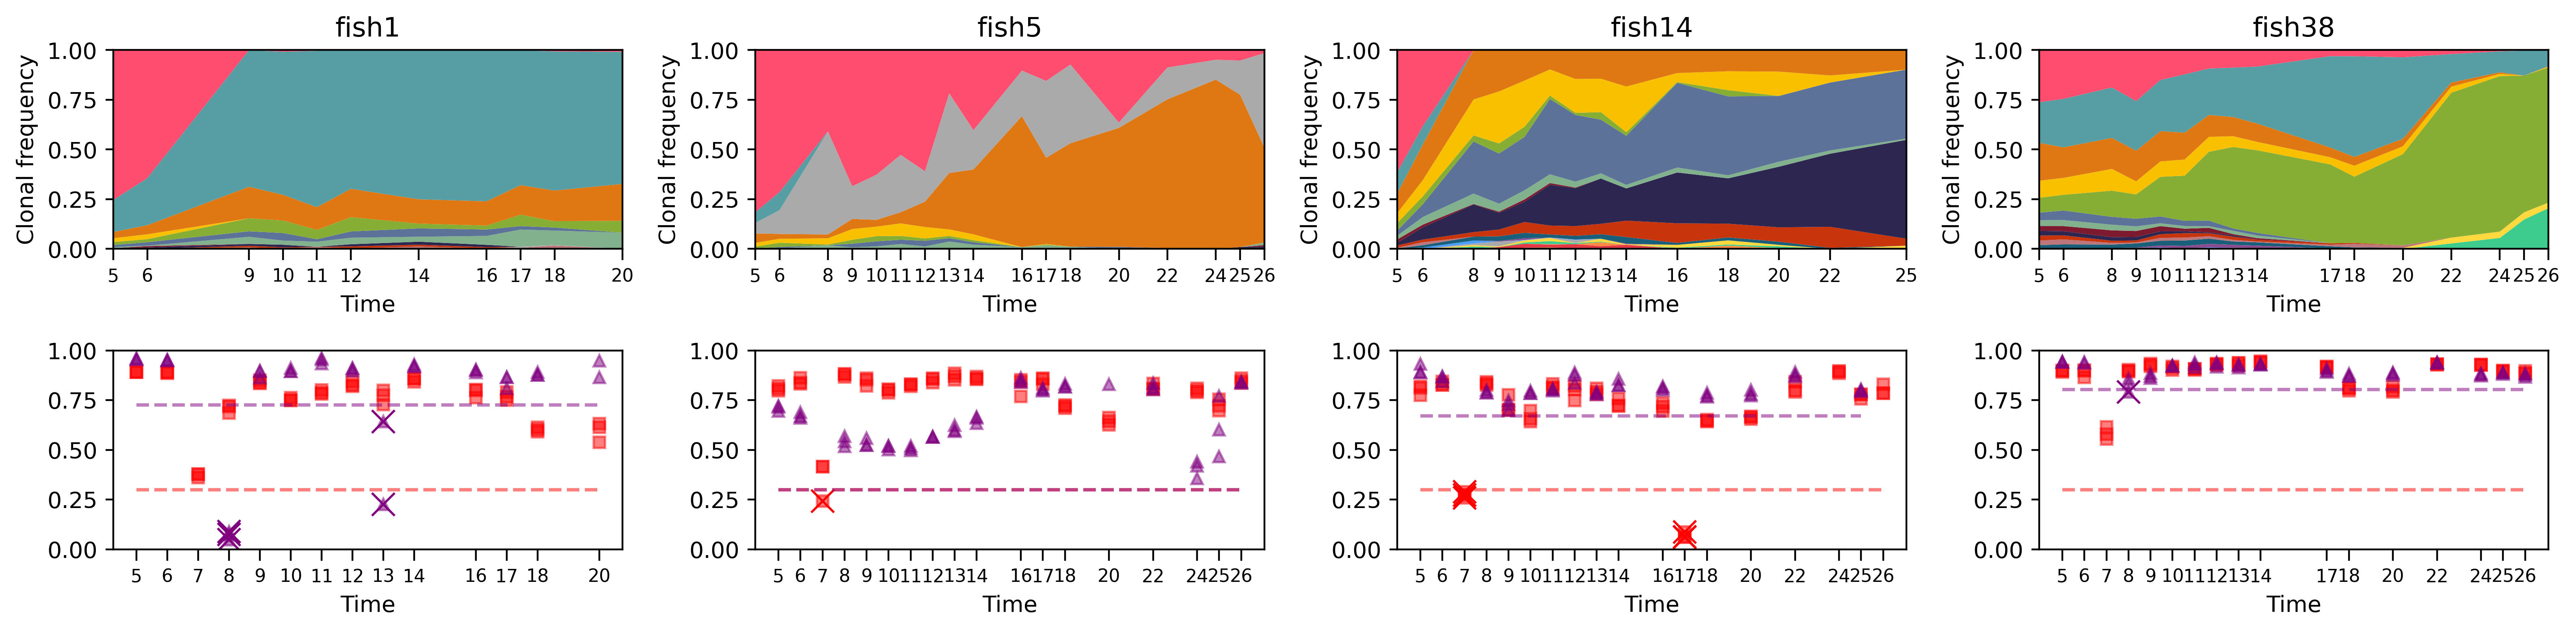

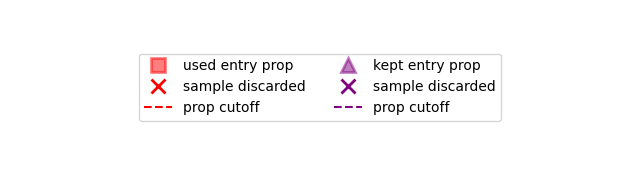

In [52]:
# Compare mullers for three sets of GESTALT parameters
# 4 fish, figure for paper

def plot_examples(data, metrics, fishes, exp):
    fig_width = 4 * 4  # 4 inches per column
    fig_height = 4
    
    fig, ax = plt.subplots(2, 4, figsize=(fig_width, fig_height), dpi=400)
    for i in range(4):
        plot_fish(fishes[i], ax[0, i], data)
        show_abnormalities(fishes[i], ax[1, i], data, metrics, interp = False, show_visual=False, map_samples=True)
        ax[0, i].tick_params(axis='x', labelsize=8, length=5)
        ax[1, i].tick_params(axis='x', labelsize=8, length=5)
    plt.savefig(f'figures/{exp}_plot.svg', format='svg')
    plt.show()

fishes = ['fish1', 'fish5', 'fish14', 'fish38']

experiment1 = 'experiment-OG'
data_file1 = f'./experiments/{experiment1}/final_data.csv'
data1 = pd.read_csv(data_file1)
metrics1 = get_abnormality_metrics(experiment1, data_folder='data/mp0.8_tq10')

plot_examples(data1, metrics1, fishes, experiment1)

experiment2 = 'experiment-MP0.95'
data_file2 = f'./experiments/{experiment2}/final_data.csv'
data2 = pd.read_csv(data_file2)
metrics2 = get_abnormality_metrics(experiment2, data_folder='data/mp0.95_tq10')

plot_examples(data2, metrics2, fishes, experiment2)

experiment3 = 'experiment-TQ14'
data_file3 = f'./experiments/{experiment3}/final_data.csv'
data3 = pd.read_csv(data_file3)
metrics3 = get_abnormality_metrics(experiment3, data_folder='data/mp0.8_tq14')

plot_examples(data3, metrics3, fishes, experiment3)

# Create custom legend
legend_elements = [
    # Red square for "used entry prop"
    plt.Line2D([0], [0], marker='s', color='red', markerfacecolor='red', 
               markersize=10, markeredgewidth=2, linestyle='None', alpha=0.5, 
               label='used entry prop'),
    plt.Line2D([0], [0], marker='x', color='red', markerfacecolor='red', 
               markersize=10, markeredgewidth=2, linestyle='None', 
               label='sample discarded'),
    plt.Line2D([0], [0], marker='None', color='red', markerfacecolor='red', 
               markersize=10, markeredgewidth=2, linestyle='--', 
               label='prop cutoff'),

    # Purple triangle for "kept entry prop"
    plt.Line2D([0], [0], marker='^', color='purple', markerfacecolor='purple', 
               markersize=10, markeredgewidth=2, linestyle='None', alpha=0.5, 
               label='kept entry prop'),
    plt.Line2D([0], [0], marker='x', color='purple', markerfacecolor='purple', 
               markersize=10, markeredgewidth=2, linestyle='None',
               label='sample discarded'),
    plt.Line2D([0], [0], marker='None', color='purple', markerfacecolor='purple', 
               markersize=10, markeredgewidth=2, linestyle='--',
               label='prop cutoff'),
]

# Create figure with no content
fig, ax = plt.subplots(figsize=(8, 2))
ax.set_axis_off()  # Hide axes

# Create legend with custom positioning
legend = ax.legend(handles=legend_elements, 
                   loc='center', 
                   ncol=2,  # Display in 2 columns
                   frameon=True)  # Keep frame

plt.savefig(f'figures/legend.svg', format='svg')
plt.show()

In [96]:
pipeline_utility.sample_map

{1: 5,
 2: 6,
 3: 7,
 4: 8,
 5: 9,
 6: 10,
 7: 11,
 8: 12,
 9: 13,
 10: 14,
 11: 16,
 12: 17,
 13: 18,
 14: 20,
 15: 22,
 16: 24,
 17: 25,
 18: 26}